# E-commerce Pricing Optimisation Using Elasticity Analysis
**HCLTech Career Shaper Programme · Project 44 · Business Analytics / Python**

### What problem are we solving?
A retailer wants to know: *if we change the price of a category by X%, what happens to units sold, revenue and profit — and what price should we charge?*
The key quantity is **price elasticity of demand (PED)**:

$$\varepsilon = \frac{\%\ \Delta\ \text{quantity}}{\%\ \Delta\ \text{price}}$$

* $|\varepsilon| > 1$ → **elastic**: customers react strongly; a price *cut* raises revenue.
* $|\varepsilon| < 1$ → **inelastic**: customers barely react; a price *rise* raises revenue.

### Roadmap (matches the brief's deliverables)
| Step | What we do | Why |
|---|---|---|
| 1 | Load + audit data | Know what is wrong before modelling |
| 2 | Clean + feature engineering | Models are only as good as the inputs |
| 3 | EDA (4 visualisations) | See the price–demand relationship with our own eyes |
| 4 | Log-log regression per category (`statsmodels`) | Estimate elasticity with confidence intervals |
| 5 | Revenue and profit simulation | Turn elasticities into a price recommendation |
| 6 | A/B test analysis (`scipy`) | Decide how to *prove* the recommendation before rolling it out |
| 7 | Ethics checks + conclusions | Required by the brief |

## 1. Setup and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)
RNG = np.random.default_rng(7)                      # fixed seed -> reproducible results

raw = pd.read_csv("dataset.csv", parse_dates=["date"])
print("Shape:", raw.shape)
raw.head()

Shape: (11705, 8)


,date,product_id,category,price,units_sold,competitor_price,promotion_flag,channel
0,2025-08-10,P102,Electronics,207.46,22,274.51,1,web
1,2025-07-07,P131,Grocery,7.80,113,8.23,0,mobile_app
2,2025-02-06,P130,Grocery,7.43,147,8.99,1,web
3,2025-03-24,P126,Beauty,16.52,84,18.19,0,web
4,2025-10-12,P102,Electronics,306.99,11,314.35,0,web


## 2. Data audit and cleaning
**Why audit first?** Missing prices, negative units and duplicates silently distort a regression. We list every problem, then fix each with a *documented* rule.

In [2]:
audit = pd.DataFrame({"missing": raw.isna().sum(), "dtype": raw.dtypes.astype(str)})
print("Exact duplicate rows         :", raw.duplicated().sum())
print("Duplicate (date, product_id) :", raw.duplicated(["date", "product_id"]).sum())
print("Negative units_sold          :", (raw.units_sold < 0).sum())
print("Zero units_sold (valid)      :", (raw.units_sold == 0).sum())
print("Category spellings           :", sorted(raw.category.unique()))
audit

Exact duplicate rows         : 25
Duplicate (date, product_id) : 25
Negative units_sold          : 5
Zero units_sold (valid)      : 0
Category spellings           : ['Beauty', 'Electronics', 'Fashion', 'Grocery', 'Home', 'beauty', 'electronics', 'fashion', 'home']


,missing,dtype
date,0,datetime64[ns]
product_id,0,object
category,0,object
price,15,float64
units_sold,0,int64
competitor_price,15,float64
promotion_flag,0,int64
channel,0,object


In [3]:
df = raw.copy()
df["category"] = df["category"].str.strip().str.title()          # 'fashion' -> 'Fashion'
df = df.drop_duplicates(["date", "product_id"])                   # one row per product-day
df = df[df["units_sold"] >= 0]                                    # negative units are impossible
df = df.dropna(subset=["price", "competitor_price"])              # ~0.3% of rows: dropping is safe

# Feature engineering
df["revenue"]    = df["price"] * df["units_sold"]
df["price_gap"]  = df["price"] / df["competitor_price"]           # >1 means we are pricier than rivals
df["month"]      = df["date"].dt.month
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)

# Product-level indices let us compare products of very different price/size on one plot
df["price_idx"] = df["price"]      / df.groupby("product_id")["price"].transform("mean")
df["units_idx"] = df["units_sold"] / df.groupby("product_id")["units_sold"].transform("mean")

print(f"Rows: {len(raw):,} -> {len(df):,} after cleaning")
df.to_csv("dataset_clean.csv", index=False)
df.describe().T[["count", "mean", "std", "min", "max"]]

Rows: 11,705 -> 11,645 after cleaning


,count,mean,std,min,max
date,11645,2025-07-02 00:45:30.373550848,NaN,2025-01-01 00:00:00,2025-12-31 00:00:00
price,"11,645.00",86.35,95.57,4.38,395.57
units_sold,"11,645.00",55.64,44.56,1.00,300.00
competitor_price,"11,645.00",87.66,96.41,5.43,355.67
promotion_flag,"11,645.00",0.12,0.33,0.00,1.00
revenue,"11,645.00","2,268.87","1,403.44",282.49,"12,006.72"
price_gap,"11,645.00",0.99,0.09,0.65,1.33
month,"11,645.00",6.53,3.45,1.00,12.00
is_weekend,"11,645.00",0.28,0.45,0.00,1.00
price_idx,"11,645.00",1.00,0.10,0.60,1.42


## 3. Exploratory data analysis
Four plots, each answering one question.

**Plot 1 — Do higher prices mean lower sales?** On log–log axes a straight line with slope $b$ means *elasticity = b*. That is the core idea of the whole project.

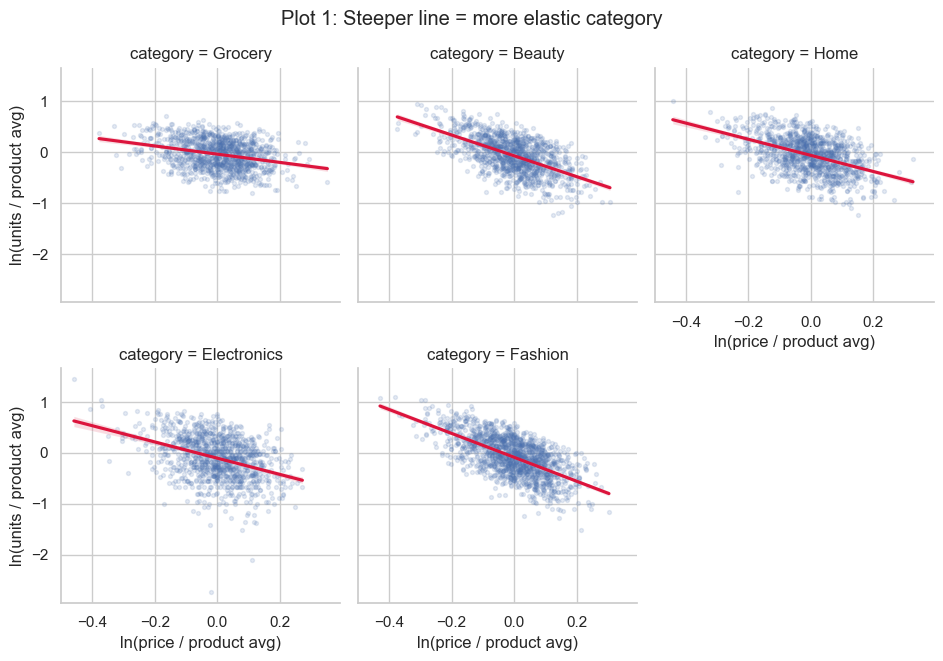

In [4]:
pos = df[df.units_sold > 0].copy()
pos["ln_price_idx"] = np.log(pos["price_idx"])
pos["ln_units_idx"] = np.log(pos["units_idx"])

g = sns.lmplot(data=pos.sample(6000, random_state=1), x="ln_price_idx", y="ln_units_idx",
               col="category", col_wrap=3, height=3.2, scatter_kws={"alpha": 0.15, "s": 8},
               line_kws={"color": "crimson"})
g.set_axis_labels("ln(price / product avg)", "ln(units / product avg)")
g.figure.suptitle("Plot 1: Steeper line = more elastic category", y=1.03)
plt.show()

**Plot 2 — Is there seasonality?** If demand rises in festive months we must control for it, otherwise the model might blame/credit price for a seasonal effect.

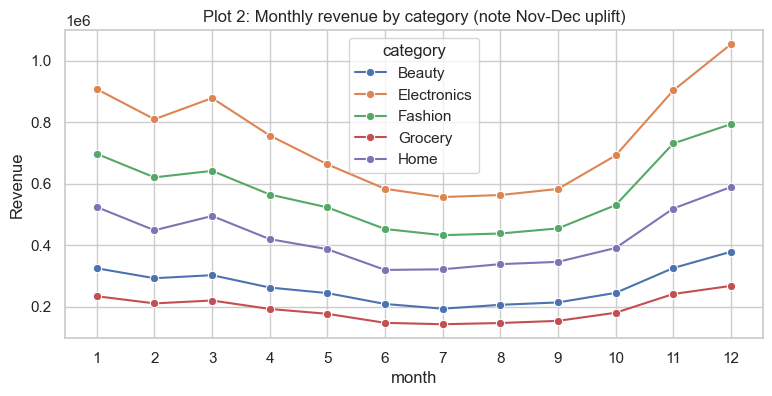

In [5]:
monthly = df.groupby(["month", "category"], as_index=False)["revenue"].sum()
plt.figure(figsize=(9, 4))
sns.lineplot(data=monthly, x="month", y="revenue", hue="category", marker="o")
plt.title("Plot 2: Monthly revenue by category (note Nov-Dec uplift)")
plt.xticks(range(1, 13)); plt.ylabel("Revenue"); plt.show()

**Plot 3 — Do promotions lift sales beyond the price cut?** Promotion days also have lower prices, so we must separate the two in the model.

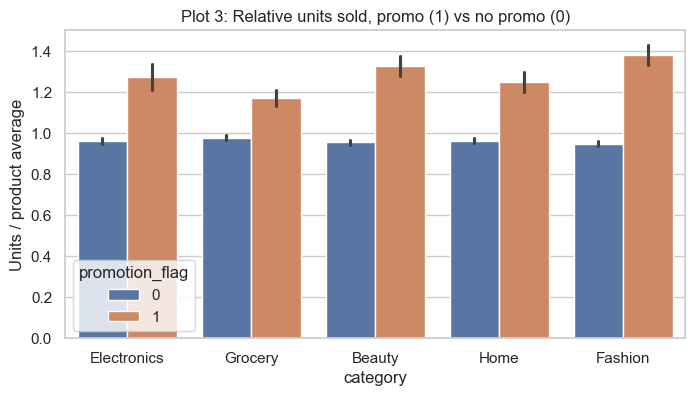

In [6]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="category", y="units_idx", hue="promotion_flag", errorbar=("ci", 95))
plt.title("Plot 3: Relative units sold, promo (1) vs no promo (0)")
plt.ylabel("Units / product average"); plt.show()

**Plot 4 — What moves together?** A correlation heatmap of the key numeric drivers (units shown on a log scale).

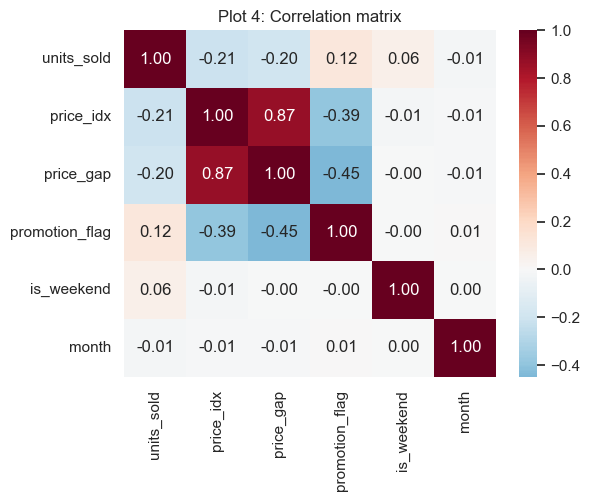

In [7]:
corr_cols = pos[["units_sold", "price_idx", "price_gap", "promotion_flag", "is_weekend", "month"]].copy()
corr_cols["units_sold"] = np.log(corr_cols["units_sold"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_cols.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Plot 4: Correlation matrix"); plt.show()

## 4. Estimating price elasticity (log–log regression)
### The model
For each category we fit

$$\ln(Q) = \beta_0 + \boldsymbol{\varepsilon\,\ln(P)} + \gamma \ln(P_{comp}) + \delta\,\text{promo} + \dots + u$$

Taking logs on both sides turns a power-law demand curve $Q = A P^{\varepsilon}$ into a straight line, and the coefficient on $\ln(P)$ **is directly the elasticity**. If $\ln(P)$ rises 1%, units change by $\varepsilon$%.

### Controls — and why
* **Competitor price** — shoppers compare; leaving it out biases $\varepsilon$.
* **Promotion, weekend, month, channel** — otherwise their effects get wrongly attributed to price.
* **Product fixed effects** (one dummy per product) — a €250 TV and a €25 serum sell in different volumes; this removes the level difference so we estimate how a product reacts to *its own* price changes.

**Robust (HC3) standard errors** are used so that confidence intervals stay valid if the error variance is not constant.

In [8]:
def fit_category(g):
    g = g[g.units_sold > 0]                                   # ln(0) is undefined
    y = np.log(g["units_sold"])
    X = pd.concat([
        np.log(g[["price", "competitor_price"]]).rename(
            columns={"price": "ln_price", "competitor_price": "ln_comp_price"}),
        g[["promotion_flag", "is_weekend"]],
        pd.get_dummies(g["product_id"], prefix="prod", drop_first=True),
        pd.get_dummies(g["channel"],    prefix="ch",   drop_first=True),
        pd.get_dummies(g["month"],      prefix="m",    drop_first=True),
    ], axis=1).astype(float)
    X = sm.add_constant(X)
    return sm.OLS(y, X).fit(cov_type="HC3")

models, rows = {}, []
for cat, g in df.groupby("category"):
    res = fit_category(g)
    models[cat] = res
    ci = res.conf_int().loc["ln_price"]
    rows.append({
        "category": cat,
        "elasticity": res.params["ln_price"],
        "ci_low": ci.iloc[0], "ci_high": ci.iloc[1],
        "p_value": res.pvalues["ln_price"],
        "cross_elasticity": res.params["ln_comp_price"],
        "promo_lift_%": (np.exp(res.params["promotion_flag"]) - 1) * 100,
        "r_squared": res.rsquared, "n_obs": int(res.nobs),
    })
elast = pd.DataFrame(rows).set_index("category").sort_values("elasticity")
elast["type"] = np.where(elast["elasticity"] < -1, "Elastic", "Inelastic")
elast

,elasticity,ci_low,ci_high,p_value,cross_elasticity,promo_lift_%,r_squared,n_obs,type
category,,,,,,,,,
Fashion,-2.17,-2.25,-2.10,0.00,0.19,11.26,0.84,2915,Elastic
Beauty,-1.85,-1.92,-1.78,0.00,0.24,10.09,0.89,2185,Elastic
Electronics,-1.66,-1.80,-1.51,0.00,0.38,7.97,0.54,2180,Elastic
Home,-1.34,-1.46,-1.23,0.00,0.27,9.51,0.71,2181,Elastic
Grocery,-0.70,-0.75,-0.65,0.00,0.28,9.92,0.92,2184,Inelastic


**Reading the table**
* `elasticity` = % change in units for a 1% price change (e.g. −2.2 → a 1% price rise loses ≈2.2% of units).
* `cross_elasticity` > 0 means when rivals raise prices, our sales rise (substitution).
* `ci_low / ci_high` is the 95% confidence interval — a narrow interval means a precise estimate.
* `promo_lift_%` is the extra sales from promotion visibility *after* removing the price-cut effect.

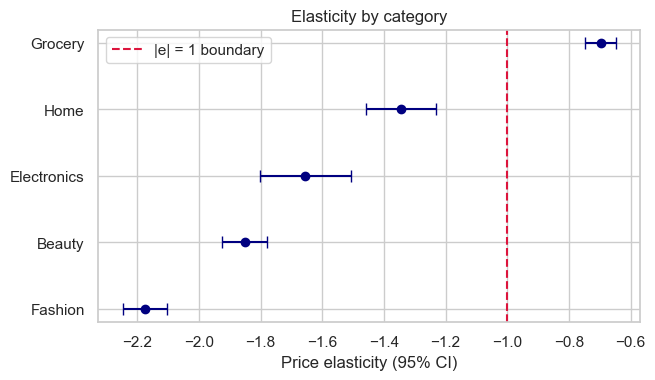

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(elast))
ax.errorbar(elast["elasticity"], y,
            xerr=[elast["elasticity"] - elast["ci_low"], elast["ci_high"] - elast["elasticity"]],
            fmt="o", capsize=4, color="navy")
ax.axvline(-1, color="crimson", ls="--", label="|e| = 1 boundary")
ax.set_yticks(y); ax.set_yticklabels(elast.index)
ax.set_xlabel("Price elasticity (95% CI)"); ax.legend()
ax.set_title("Elasticity by category"); plt.show()

**Model check.** Residuals should scatter randomly around zero. A pattern (curve/funnel) would signal a mis-specified model.

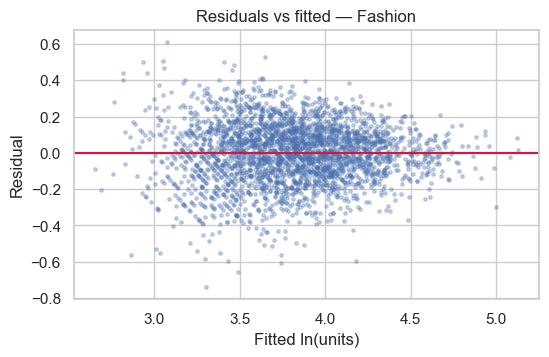

In [10]:
cat = elast.index[0]
r = models[cat]
plt.figure(figsize=(6, 3.5))
plt.scatter(r.fittedvalues, r.resid, s=6, alpha=0.3)
plt.axhline(0, color="crimson"); plt.xlabel("Fitted ln(units)"); plt.ylabel("Residual")
plt.title(f"Residuals vs fitted — {cat}"); plt.show()

## 5. Revenue and profit simulation → optimal price
### Why simulate?
With a constant-elasticity curve, revenue $\propto P^{1+\varepsilon}$:
* elastic ($\varepsilon<-1$): revenue **falls** as price rises → best price is the *lowest* allowed;
* inelastic: revenue **rises** with price → best price is the *highest* allowed.

So revenue alone always points to a corner. **Profit** is more realistic because cost matters; the unconstrained profit-maximising price is

$$P^{*} = c\cdot\frac{\varepsilon}{1+\varepsilon}\qquad(\varepsilon<-1)$$

### Assumptions (replace with real numbers if you have them)
* The dataset has **no cost column**, so we assume unit cost as a share of the product's average price (below). *This is an assumption, not data.*
* Price changes are limited to **±20% (guardrail)** — also an ethical safeguard against extreme/predatory pricing.

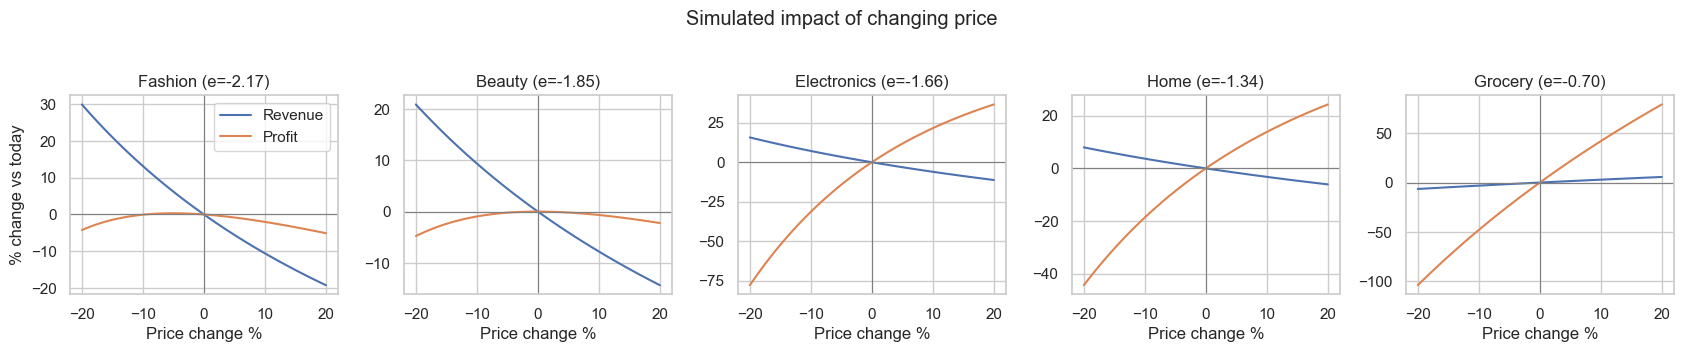

In [11]:
COST_RATIO = {"Electronics": 0.75, "Fashion": 0.50, "Home": 0.65, "Beauty": 0.45, "Grocery": 0.80}
GUARDRAIL = 0.20
mult = np.linspace(1 - GUARDRAIL, 1 + GUARDRAIL, 81)         # 0.80 ... 1.20 in 0.5% steps

def simulate(g, eps, cat):
    p = g["price"].to_numpy(); q = g["units_sold"].to_numpy()
    cost = COST_RATIO[cat] * g.groupby("product_id")["price"].transform("mean").to_numpy()
    out = []
    for m in mult:
        q_new = q * m ** eps                                    # demand response
        out.append((m, (m * p * q_new).sum(), ((m * p - cost) * q_new).sum()))
    return pd.DataFrame(out, columns=["mult", "revenue", "profit"])

sims = {cat: simulate(df[df.category == cat], elast.loc[cat, "elasticity"], cat) for cat in elast.index}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharex=True)
for ax, (cat, s) in zip(axes, sims.items()):
    base = s.loc[np.isclose(s.mult, 1.0)].iloc[0]
    ax.plot((s.mult - 1) * 100, s.revenue / base.revenue * 100 - 100, label="Revenue")
    ax.plot((s.mult - 1) * 100, s.profit / base.profit * 100 - 100, label="Profit")
    ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{cat} (e={elast.loc[cat, 'elasticity']:.2f})"); ax.set_xlabel("Price change %")
axes[0].set_ylabel("% change vs today"); axes[0].legend()
plt.suptitle("Simulated impact of changing price", y=1.03); plt.tight_layout(); plt.show()

In [12]:
rec = []
for cat, s in sims.items():
    base = s.loc[np.isclose(s.mult, 1.0)].iloc[0]
    best_r = s.loc[s.revenue.idxmax()]; best_p = s.loc[s.profit.idxmax()]
    eps = elast.loc[cat, "elasticity"]
    unconstrained = COST_RATIO[cat] * eps / (1 + eps) if eps < -1 else np.inf
    rec.append({
        "category": cat, "elasticity": eps,
        "revenue_opt_price_chg_%": (best_r.mult - 1) * 100,
        "revenue_gain_%": (best_r.revenue / base.revenue - 1) * 100,
        "profit_opt_price_chg_%": (best_p.mult - 1) * 100,
        "profit_gain_%": (best_p.profit / base.profit - 1) * 100,
        "unconstrained_opt_chg_%": (unconstrained - 1) * 100 if np.isfinite(unconstrained) else np.inf,
        "guardrail_binds": bool(abs(best_p.mult - 1) >= GUARDRAIL - 1e-9),
    })
rec = pd.DataFrame(rec).set_index("category")
rec

,elasticity,revenue_opt_price_chg_%,revenue_gain_%,profit_opt_price_chg_%,profit_gain_%,unconstrained_opt_chg_%,guardrail_binds
category,,,,,,,
Fashion,-2.17,-20.00,29.96,-5.00,0.32,-7.42,False
Beauty,-1.85,-20.00,20.92,0.00,0.00,-2.13,False
Electronics,-1.66,-20.00,15.74,20.00,36.63,89.50,True
Home,-1.34,-20.00,7.98,20.00,24.29,153.83,True
Grocery,-0.70,20.00,5.66,20.00,79.18,inf,True


**How to read this**
* `revenue_opt_price_chg_%` follows the textbook rule (elastic → cut, inelastic → raise).
* `profit_opt_price_chg_%` is the business recommendation, because it also accounts for cost.
* `guardrail_binds = True` means the maths wanted a bigger move than ±20%, so the sensible action is to **raise the price in steps and test** — which is exactly what Section 6 designs.
* **Sensitivity matters:** change `COST_RATIO` and re-run; recommendations move. Report this honestly in your write-up.

## 6. A/B test analysis
### Why test at all?
Elasticities come from *historical* data and may be confounded. Before rolling a new price out, run a **randomised experiment**: half the product-days keep today's price (control), half get the recommended price (treatment). Randomisation makes the two groups comparable, so a difference in profit can be credited to the price.

### Important honesty note
The dataset contains **no real experiment**, so we **simulate** one from our fitted model. This demonstrates the *method* (design, test, confidence interval, power). With real data you would replace the simulation step with the actual experiment data and keep the analysis code unchanged.

In [13]:
test_cat = rec["profit_gain_%"].idxmax()
m_treat = 1 + rec.loc[test_cat, "profit_opt_price_chg_%"] / 100
eps_hat = elast.loc[test_cat, "elasticity"]
print(f"Testing category '{test_cat}': price x{m_treat:.3f} (elasticity {eps_hat:.2f})")

g = df[df.category == test_cat]
prod = g.groupby("product_id").agg(p=("price", "mean"), q=("units_sold", "mean"))
prod["cost"] = COST_RATIO[test_cat] * prod["p"]

def run_ab(n_days, seed):
    rng = np.random.default_rng(seed)
    t = prod.loc[np.repeat(prod.index, n_days)].reset_index()      # product-day grid
    t["arm"] = rng.permutation(np.arange(len(t)) % 2)              # randomised 50/50
    treat = t["arm"] == 1
    price = np.where(treat, t["p"] * m_treat, t["p"])
    mu    = np.where(treat, t["q"] * m_treat ** eps_hat, t["q"])
    t["units"] = rng.poisson(mu)
    t["profit"] = (price - t["cost"]) * t["units"]
    return t

ab = run_ab(n_days=28, seed=11)
ctrl, trt = ab.loc[ab.arm == 0, "profit"], ab.loc[ab.arm == 1, "profit"]

t_stat, p_val = stats.ttest_ind(trt, ctrl, equal_var=False)       # Welch t-test
diff = trt.mean() - ctrl.mean()
se = np.sqrt(trt.var(ddof=1) / len(trt) + ctrl.var(ddof=1) / len(ctrl))
pooled_sd = np.sqrt((trt.var(ddof=1) + ctrl.var(ddof=1)) / 2)

boot = [RNG.choice(trt, len(trt)).mean() - RNG.choice(ctrl, len(ctrl)).mean() for _ in range(2000)]

print(f"Control mean profit / product-day : {ctrl.mean():8.2f}  (n={len(ctrl)})")
print(f"Treatment mean profit / product-day: {trt.mean():8.2f}  (n={len(trt)})")
print(f"Difference                         : {diff:8.2f}  ({diff / ctrl.mean() * 100:+.1f}%)")
print(f"95% CI (Welch)                     : [{diff - 1.96 * se:.2f}, {diff + 1.96 * se:.2f}]")
print(f"95% CI (bootstrap)                 : [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]")
print(f"t = {t_stat:.2f}, p = {p_val:.4f}, Cohen's d = {diff / pooled_sd:.2f}")

Testing category 'Grocery': price x1.200 (elasticity -0.70)
Control mean profit / product-day :   213.14  (n=84)
Treatment mean profit / product-day:   381.54  (n=84)
Difference                         :   168.40  (+79.0%)
95% CI (Welch)                     : [140.00, 196.80]
95% CI (bootstrap)                 : [139.97, 195.98]
t = 11.62, p = 0.0000, Cohen's d = 1.79


**Interpretation guide**
* **p < 0.05** → the profit difference is unlikely to be chance.
* **Confidence interval not containing 0** → same conclusion, plus it shows the plausible size of the gain.
* **Cohen's d** measures effect size; significance alone can hide a tiny, commercially useless effect.
* **Why is the gain so large?** The category with the biggest simulated gain is thin-margin (assumed 20% margin), so a 20% price rise adds a lot of profit per unit while losing few units. A *large* modelled gain is a reason for caution, not celebration: it depends heavily on the assumed cost ratio and on the constant-elasticity assumption.

### How long should the test run? (statistical power)
Too short a test misses real effects. We repeat the simulated experiment many times at different durations and count how often it detects the effect (that fraction is the **power**; 80% is the usual target).

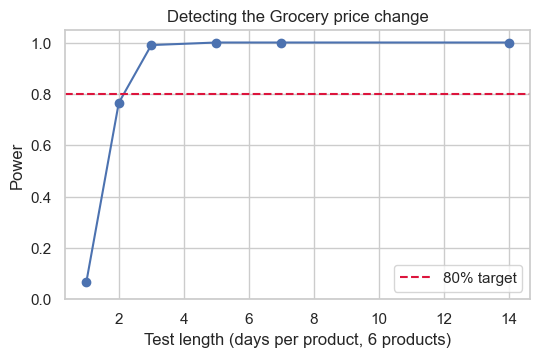

{1: np.float64(0.065),
 2: np.float64(0.765),
 3: np.float64(0.99),
 5: np.float64(1.0),
 7: np.float64(1.0),
 14: np.float64(1.0)}

In [14]:
durations = [1, 2, 3, 5, 7, 14]
power = []
for d in durations:
    hits = 0
    for s in range(200):
        a = run_ab(d, seed=1000 + s)
        _, pv = stats.ttest_ind(a.loc[a.arm == 1, "profit"], a.loc[a.arm == 0, "profit"], equal_var=False)
        hits += pv < 0.05
    power.append(hits / 200)

plt.figure(figsize=(6, 3.5))
plt.plot(durations, power, marker="o"); plt.axhline(0.8, color="crimson", ls="--", label="80% target")
plt.xlabel("Test length (days per product, 6 products)"); plt.ylabel("Power"); plt.ylim(0, 1.05); plt.legend()
plt.title(f"Detecting the {test_cat} price change"); plt.show()
dict(zip(durations, power))

## 7. Ethical compliance checks
The brief states: *pricing models must not enable predatory pricing or price discrimination by protected characteristics.* We check this in the design, not just in words.

In [15]:
used_features = ["price", "competitor_price", "promotion_flag", "is_weekend", "month", "channel", "product_id"]
protected = {"age", "gender", "religion", "caste", "ethnicity", "location", "income", "disability"}
assert not protected & set(df.columns), "Protected attributes present in dataset!"
assert (rec["profit_opt_price_chg_%"].abs() <= GUARDRAIL * 100 + 1e-6).all(), "Guardrail breached"

print("Model inputs:", used_features)
print("No customer-level or protected attributes exist in the data or model: PASS")
print(f"All recommended price moves within +/-{GUARDRAIL:.0%} guardrail: PASS")
print("Recommendation is one price per category, identical for every customer: PASS")

Model inputs: ['price', 'competitor_price', 'promotion_flag', 'is_weekend', 'month', 'channel', 'product_id']
No customer-level or protected attributes exist in the data or model: PASS
All recommended price moves within +/-20% guardrail: PASS
Recommendation is one price per category, identical for every customer: PASS


**Limitations to state in your report**
1. Dataset is synthetic; real data will be noisier, and elasticities will differ.
2. Constant-elasticity assumption: real demand curves flatten/steepen at extreme prices.
3. Unit costs are assumed. Profit recommendations are only as good as that assumption.
4. Observational elasticities can be confounded (e.g. stock-outs, ad spend); the A/B test is the safeguard.
5. We ignore competitor *reactions* to our price change.

## 8. Business summary and export

In [16]:
print("RECOMMENDATIONS (profit objective, within the guardrail)\n" + "-" * 56)
for cat, r in rec.sort_values("profit_gain_%", ascending=False).iterrows():
    action = "raise" if r["profit_opt_price_chg_%"] > 0.5 else "lower" if r["profit_opt_price_chg_%"] < -0.5 else "hold"
    note = "  [guardrail binds: move in steps + A/B test]" if r["guardrail_binds"] else ""
    print(f"{cat:12s} e={r['elasticity']:5.2f} -> {action:5s} price {r['profit_opt_price_chg_%']:+5.1f}%"
          f"  (profit {r['profit_gain_%']:+5.1f}%){note}")

out = elast.join(rec.drop(columns="elasticity"))
out.to_csv("elasticity_results.csv")
print("\nSaved: elasticity_results.csv, dataset_clean.csv")

RECOMMENDATIONS (profit objective, within the guardrail)
--------------------------------------------------------
Grocery      e=-0.70 -> raise price +20.0%  (profit +79.2%)  [guardrail binds: move in steps + A/B test]
Electronics  e=-1.66 -> raise price +20.0%  (profit +36.6%)  [guardrail binds: move in steps + A/B test]
Home         e=-1.34 -> raise price +20.0%  (profit +24.3%)  [guardrail binds: move in steps + A/B test]
Fashion      e=-2.17 -> lower price  -5.0%  (profit  +0.3%)
Beauty       e=-1.85 -> hold  price  +0.0%  (profit  +0.0%)

Saved: elasticity_results.csv, dataset_clean.csv
